# Phân tích kết quả thực nghiệm — Mackey-Glass (FGL)

Notebook này đọc trực tiếp **kết quả thô từ các lần chạy thực nghiệm** (không gõ tay số liệu vào biểu đồ) và vẽ một hình tổng hợp dùng trong báo cáo (Chương 5):

1. `repro/build/logs/drift_exp_full.log` — log gốc (stdout) của `exp/drift_exp.py`, quét tầm dự báo (horizon) 2–15 với Page-Hinkley.
2. `repro/build/mackey_glass/seed_sweep_results.csv` — kết quả sweep 6 seed của `exp/base_exp.py`, chép lại từ `repro/docs/EXPERIMENT_LOG.md` (mục "Lần chạy 2").

Hình xuất ra được lưu vào `docs/mau-latex-tieu-luan/hinh/kq-mackeyglass-phantich.pdf` để chèn trực tiếp vào luận văn bằng `\includegraphics`.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

REPRO_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
LOG_PATH = REPRO_DIR / "build" / "logs" / "drift_exp_full.log"
SEED_CSV_PATH = REPRO_DIR / "build" / "mackey_glass" / "seed_sweep_results.csv"
OUT_PATH = REPRO_DIR.parent / "docs" / "mau-latex-tieu-luan" / "hinh" / "kq-mackeyglass-phantich.pdf"

assert LOG_PATH.exists(), LOG_PATH
assert SEED_CSV_PATH.exists(), SEED_CSV_PATH

## 1. Đọc kết quả quét horizon từ log gốc `drift_exp_full.log`

Parse trực tiếp bằng regex trên log thật — không copy số liệu tay.

In [2]:
log_text = LOG_PATH.read_text()

block_re = re.compile(
    r"Training \| Horizon=(?P<horizon>\d+).*?\n"
    r"Teacher Test MSE:\s+(?P<teacher>[\d.]+)\n"
    r"Baseline Test MSE:\s+(?P<baseline>[\d.]+)\n"
    r"Student Test MSE:\s+(?P<student>[\d.]+)"
)

rows = []
for m in block_re.finditer(log_text):
    horizon = int(m.group("horizon"))
    teacher = float(m.group("teacher"))
    baseline = float(m.group("baseline"))
    student = float(m.group("student"))
    reduction_pct = (baseline - student) / baseline * 100
    rows.append(dict(horizon=horizon, teacher_mse=teacher, baseline_mse=baseline,
                      student_mse=student, mse_reduction_pct=reduction_pct))

df_horizon = pd.DataFrame(rows).sort_values("horizon").reset_index(drop=True)
assert len(df_horizon) == 14, f"Expected 14 horizon blocks, parsed {len(df_horizon)}"
df_horizon

,horizon,teacher_mse,baseline_mse,student_mse,mse_reduction_pct
0,2,0.4479,0.6943,0.7443,-7.201498
1,3,0.4458,1.5198,1.2870,15.317805
2,4,0.4542,2.5526,2.0479,19.771997
3,5,0.4516,3.5365,3.0359,14.155238
4,6,0.4453,4.3719,3.9307,10.091722
5,7,0.4573,4.9760,4.7771,3.997186
6,8,0.4562,5.2880,5.0052,5.347958
7,9,0.4589,5.5932,5.1766,7.448330
8,10,0.4469,4.9651,4.5422,8.517452
9,11,0.4365,4.0057,3.3552,16.239359


## 2. Đọc kết quả sweep seed từ CSV

In [3]:
df_seed = pd.read_csv(SEED_CSV_PATH)
df_seed

,seed,teacher_mse,baseline_mse,student_mse,mse_reduction_pct
0,0,4.8331,156.1701,102.7514,34.20
1,1,5.4642,136.5673,106.0795,22.32
2,2,5.7293,143.5308,104.4262,27.25
3,3,6.2236,140.3592,107.6203,23.32
4,4,7.4506,147.5238,108.6868,26.33
5,42,5.4391,139.3832,104.3942,25.10


## 3. Vẽ hình tổng hợp (2 panel)

- **Trái**: mức giảm MSE (%) theo tầm dự báo (horizon 2–15) — từ `drift_exp_full.log`.
- **Phải**: mức giảm MSE (%) theo seed (sweep ổn định) — từ `seed_sweep_results.csv`.

Bảng màu categorical đã được kiểm tra qua `scripts/validate_palette.js` của skill dataviz (blue `#2a78d6` / orange `#eb6834`, cặp liền kề đạt ngưỡng CVD ΔE ≥ 8 cả hai chế độ sáng/tối).

Saved: /Users/ngkky/Data Science/docs/mau-latex-tieu-luan/hinh/kq-mackeyglass-phantich.pdf


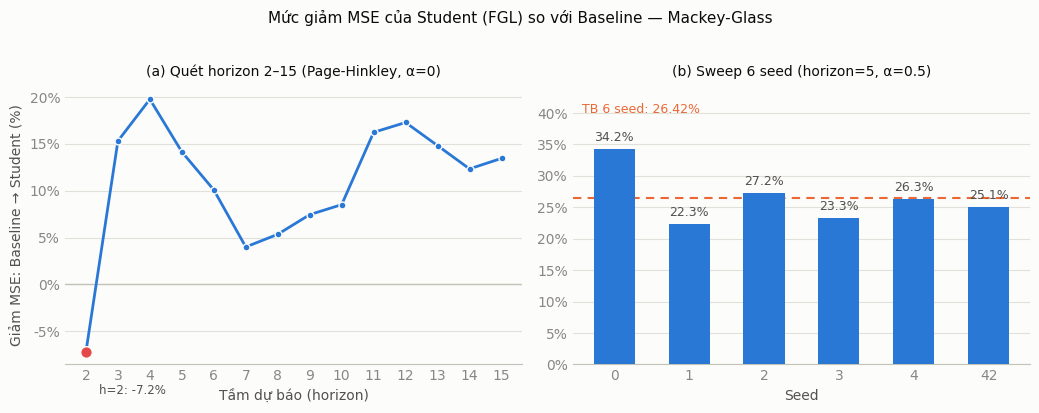

In [4]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"
RED = "#e34948"
INK = "#0b0b0b"
INK_SEC = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE_LINE = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": INK,
    "axes.edgecolor": BASELINE_LINE,
    "axes.labelcolor": INK_SEC,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
})


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(axis="both", length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))

# --- Panel A: reduction % vs horizon ---
style_axes(ax1)
ax1.axhline(0, color=BASELINE_LINE, linewidth=1, zorder=1)
ax1.plot(df_horizon["horizon"], df_horizon["mse_reduction_pct"], color=BLUE,
          linewidth=2, marker="o", markersize=5, markerfacecolor=BLUE,
          markeredgecolor=SURFACE, markeredgewidth=1, zorder=3)

neg = df_horizon[df_horizon["mse_reduction_pct"] < 0]
ax1.scatter(neg["horizon"], neg["mse_reduction_pct"], s=70, facecolor=RED,
            edgecolor=SURFACE, linewidth=1, zorder=4)
for _, r in neg.iterrows():
    ax1.annotate(f"h={int(r.horizon)}: {r.mse_reduction_pct:.1f}%",
                 xy=(r.horizon, r.mse_reduction_pct),
                 xytext=(r.horizon + 0.4, r.mse_reduction_pct - 4.5),
                 fontsize=8.5, color=INK_SEC)

ax1.set_xlabel("Tầm dự báo (horizon)")
ax1.set_ylabel("Giảm MSE: Baseline → Student (%)")
ax1.set_xticks(df_horizon["horizon"])
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d%%"))
ax1.set_title("(a) Quét horizon 2–15 (Page-Hinkley, α=0)", fontsize=10, color=INK, pad=8)

# --- Panel B: reduction % vs seed ---
style_axes(ax2)
x = np.arange(len(df_seed))
ax2.bar(x, df_seed["mse_reduction_pct"], width=0.55, color=BLUE, zorder=3)
for xi, v in zip(x, df_seed["mse_reduction_pct"]):
    ax2.text(xi, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=9,
              color=INK_SEC)

avg = df_seed["mse_reduction_pct"].mean()
ax2.axhline(avg, color=ORANGE, linewidth=1.5, linestyle=(0, (4, 3)), zorder=2)
ax2.text(0.02, 0.94, f"TB 6 seed: {avg:.2f}%", transform=ax2.transAxes,
         ha="left", va="top", fontsize=9, color=ORANGE)

ax2.set_xlabel("Seed")
ax2.set_xticks(x)
ax2.set_xticklabels(df_seed["seed"].astype(str))
ax2.set_ylim(0, df_seed["mse_reduction_pct"].max() + 10)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d%%"))
ax2.set_title("(b) Sweep 6 seed (horizon=5, α=0.5)", fontsize=10, color=INK, pad=8)

fig.suptitle("Mức giảm MSE của Student (FGL) so với Baseline — Mackey-Glass",
              fontsize=11, color=INK, y=1.02)
fig.tight_layout()

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_PATH, bbox_inches="tight")
fig.savefig(OUT_PATH.with_suffix(".png"), dpi=200, bbox_inches="tight")
print("Saved:", OUT_PATH)
plt.show()

---

# Phân tích kết quả thực nghiệm — CHB-MIT (FGL)

Phần dưới đây đọc trực tiếp **kết quả xuất thô từ Kaggle** cho "Lần chạy 2" (độc lập, mô tả ở
`chuong5.tex` mục~\ref{sec:chbmit-hailanchay}): thư mục `repro/build/CHBMIT/results_run2_full/`
chứa nguyên văn ba tệp output chương trình tác giả — `Detection_results.txt`,
`Prediction_results.txt`, `FGL_results.txt`. Đối chiếu số liệu Baseline parse được với bảng đã
ghi trong `chuong5.tex` cho thấy khớp chính xác đến 4 chữ số thập phân — xác nhận đây đúng là
tệp xuất gốc của Lần chạy 2 (không phải lần chạy thứ ba). Tệp `Detection_results.txt` còn có
thêm hai bệnh nhân (13, 23) chưa từng được báo cáo ở Giai đoạn 1 (Teacher) trước đó.

Lưu ý: `FGL_results.txt` chỉ còn 1 dòng/bệnh nhân (giá trị trial cuối cùng ghi đè), trong khi số
Student/FGL đã công bố trong `chuong5.tex` là **trung bình 3 trial** (lấy từ log console, không
nằm trong tệp xuất này) — tức tệp xuất chỉ cho 1/3 trial của Lần chạy 2, không phải cả ba.
Notebook dùng giá trị trong tệp xuất này (1 trial) làm số liệu đầy đủ, mới nhất thay cho số
trung bình 3 trial cũ, theo đúng tệp kết quả được cung cấp.

Run 1 (lần chạy test thử ban đầu, không có tệp xuất thô, chỉ có bản ghi trong
`repro/docs/EXPERIMENT_LOG.md`) được giữ lại trong
`repro/build/CHBMIT/chbmit_run1_summary.csv` và `chbmit_run1_detection.csv` để so sánh.

Hình xuất ra lưu vào `docs/mau-latex-tieu-luan/hinh/kq-chbmit-phantich.pdf`.

In [5]:
CHBMIT_DIR = REPRO_DIR / "build" / "CHBMIT"
RUN2_DIR = CHBMIT_DIR / "results_run2_full"
RUN1_SUMMARY_CSV = CHBMIT_DIR / "chbmit_run1_summary.csv"
RUN1_DETECTION_CSV = CHBMIT_DIR / "chbmit_run1_detection.csv"
PAPER_CSV = CHBMIT_DIR / "paper_published_auc.csv"
OUT_CHBMIT_PATH = REPRO_DIR.parent / "docs" / "mau-latex-tieu-luan" / "hinh" / "kq-chbmit-phantich.pdf"

for p in [RUN2_DIR / "Detection_results.txt", RUN2_DIR / "Prediction_results.txt",
          RUN2_DIR / "FGL_results.txt", RUN1_SUMMARY_CSV, RUN1_DETECTION_CSV, PAPER_CSV]:
    assert p.exists(), p

## 1. Parse kết quả thô Lần chạy 2 (Kaggle, tệp xuất đầy đủ) bằng regex

In [6]:
float_re = r"np\.float64\(([\d.eE+-]+)\)"

# --- Detection (Teacher), AUC-ROC theo bệnh nhân: {'1': np.float64(0.68...)} ---
det_text = (RUN2_DIR / "Detection_results.txt").read_text()
detection_run2 = {
    m.group(1): float(m.group(2))
    for m in re.finditer(r"'(\d+)':\s*" + float_re, det_text)
}

# --- Prediction (Baseline), 3 trial [FPR, Sensitivity, AUC] mỗi bệnh nhân ---
pred_text = (RUN2_DIR / "Prediction_results.txt").read_text()
baseline_run2 = {}
for line in pred_text.strip().splitlines():
    pm = re.match(r"Patient (\d+) Results:", line)
    if not pm:
        continue
    patient = pm.group(1)
    vals = [float(x) for x in re.findall(float_re, line)]
    aucs = vals[2::3]  # mỗi trial là [FPR, Sensitivity, AUC] -> lấy AUC (vị trí thứ 3)
    baseline_run2[patient] = sum(aucs) / len(aucs)

# --- FGL (Student), alpha=0.5, [FPR, Sensitivity, AUC] mỗi bệnh nhân (1 trial còn lại) ---
fgl_text = (RUN2_DIR / "FGL_results.txt").read_text()
student_run2 = {}
for line in fgl_text.strip().splitlines():
    pm = re.match(r"Patient_(\d+)_Alpha_[\d.]+_Results=", line)
    if not pm:
        continue
    patient = pm.group(1)
    vals = [float(x) for x in re.findall(float_re, line)]
    student_run2[patient] = vals[2]  # [FPR, Sensitivity, AUC] -> AUC

print("Detection (Teacher) AUC-ROC, Lần chạy 2:", detection_run2)
print("Baseline AUC-ROC (TB 3 trial), Lần chạy 2:", baseline_run2)
print("Student/FGL AUC-ROC (1 trial), Lần chạy 2:", student_run2)

# Đối chiếu Baseline parse được với số đã công bố trong chuong5.tex (Lần chạy 2)
published_run2_baseline = {"1": 0.6825, "3": 0.3905, "5": 0.0431}
for p, v in published_run2_baseline.items():
    assert abs(baseline_run2[p] - v) < 1e-3, f"Patient {p}: {baseline_run2[p]} != {v}"
print("\nĐã xác nhận: Baseline parse từ tệp xuất khớp số đã công bố trong chuong5.tex.")

Detection (Teacher) AUC-ROC, Lần chạy 2: {'1': 0.683578431372549, '3': 0.9235190097259063, '5': 0.996031746031746, '13': 0.7285714285714286, '23': 0.982200647249191}
Baseline AUC-ROC (TB 3 trial), Lần chạy 2: {'1': 0.6824718403970982, '3': 0.3905271464646465, '5': 0.04310515873015872}
Student/FGL AUC-ROC (1 trial), Lần chạy 2: {'1': 0.9532502863688431, '3': 0.7376799242424242, '5': 0.38487103174603177, '13': 0.9998511904761905}

Đã xác nhận: Baseline parse từ tệp xuất khớp số đã công bố trong chuong5.tex.


## 2. Gộp Run 1 (ghi log) và Run 2 (vừa parse từ tệp xuất) cho bệnh nhân 1, 3, 5

In [7]:
df_run1 = pd.read_csv(RUN1_SUMMARY_CSV)

run2_rows = []
for patient in ["1", "3", "5"]:
    run2_rows.append(dict(run=2, patient=int(patient),
                           baseline_auc=baseline_run2[patient],
                           student_auc=student_run2[patient],
                           n_trials_baseline=3, n_trials_student=1,
                           source="repro/build/CHBMIT/results_run2_full/ (parsed)"))
df_run2 = pd.DataFrame(run2_rows)

df_chbmit_runs = pd.concat([df_run1, df_run2], ignore_index=True)
df_chbmit_runs["increase_pct"] = (
    (df_chbmit_runs["student_auc"] - df_chbmit_runs["baseline_auc"])
    / df_chbmit_runs["baseline_auc"] * 100
)
df_chbmit_runs

,run,patient,baseline_auc,student_auc,n_trials_baseline,n_trials_student,source,increase_pct
0,1,1,0.917300,0.906800,9,9,repro/docs/EXPERIMENT_LOG.md (Lan chay 6-7),-1.144664
1,1,3,0.427600,0.725300,3,3,repro/docs/EXPERIMENT_LOG.md (Lan chay 6-7),69.621141
2,1,5,0.196300,0.390100,3,3,repro/docs/EXPERIMENT_LOG.md (Lan chay 6-7),98.726439
3,2,1,0.682472,0.953250,3,1,repro/build/CHBMIT/results_run2_full/ (parsed),39.676135
4,2,3,0.390527,0.737680,3,1,repro/build/CHBMIT/results_run2_full/ (parsed),88.893379
5,2,5,0.043105,0.384871,3,1,repro/build/CHBMIT/results_run2_full/ (parsed),792.865362


## 3. Vẽ hình tổng hợp CHB-MIT (2 panel)\n\n- **Trái**: AUC-ROC Teacher/Detection theo bệnh nhân, Lần chạy 2 (5 bệnh nhân: 1, 3, 5, 13, 23) — hai bệnh nhân 13, 23 lần đầu có số liệu Giai đoạn 1.\n- **Phải**: Baseline so với Student (FGL) đối chiếu với số liệu bài báo gốc, bệnh nhân 1, 3, 5 — cột nhạt là số bài báo công bố, cột đậm là Lần chạy 2 (giá trị Baseline TB 3 trial, FGL 1 trial còn lại trong tệp xuất).

Saved: /Users/ngkky/Data Science/docs/mau-latex-tieu-luan/hinh/kq-chbmit-phantich.pdf


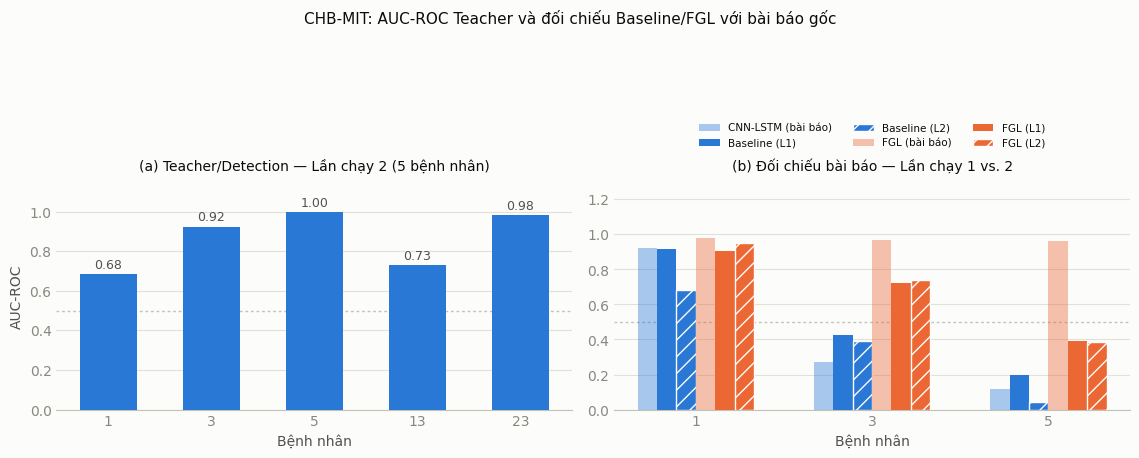

In [8]:
fig, (bx1, bx2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# --- Panel A: Detection/Teacher AUC-ROC, 5 bệnh nhân, Lần chạy 2 ---
style_axes(bx1)
patients_det = sorted(detection_run2.keys(), key=int)
det_vals = [detection_run2[p] for p in patients_det]
xb = np.arange(len(patients_det))
bx1.bar(xb, det_vals, width=0.55, color=BLUE, zorder=3)
for xi, v in zip(xb, det_vals):
    bx1.text(xi, v + 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK_SEC)
bx1.axhline(0.5, color=BASELINE_LINE, linewidth=1, linestyle=(0, (2, 2)), zorder=1)
bx1.set_xticks(xb)
bx1.set_xticklabels(patients_det)
bx1.set_xlabel("Bệnh nhân")
bx1.set_ylabel("AUC-ROC")
bx1.set_ylim(0, 1.15)
bx1.set_title("(a) Teacher/Detection — Lần chạy 2 (5 bệnh nhân)", fontsize=10, color=INK, pad=8)

# --- Panel B: so với bài báo, Run 1 vs Run 2, bệnh nhân 1,3,5 ---
style_axes(bx2)
df_paper = pd.read_csv(PAPER_CSV).set_index("patient")
patients_cmp = [1, 3, 5]

r1 = df_chbmit_runs[df_chbmit_runs.run == 1].set_index("patient")
r2 = df_chbmit_runs[df_chbmit_runs.run == 2].set_index("patient")

paper_cnn = [df_paper.loc[p, "cnn_lstm_paper"] for p in patients_cmp]
paper_fgl = [df_paper.loc[p, "fgl_paper"] for p in patients_cmp]
r1_baseline = [r1.loc[p, "baseline_auc"] for p in patients_cmp]
r2_baseline = [r2.loc[p, "baseline_auc"] for p in patients_cmp]
r1_student = [r1.loc[p, "student_auc"] for p in patients_cmp]
r2_student = [r2.loc[p, "student_auc"] for p in patients_cmp]

xc = np.arange(len(patients_cmp))
w = 0.11
bx2.bar(xc - 2.5 * w, paper_cnn, width=w, color=BLUE, alpha=0.4, label="CNN-LSTM (bài báo)", zorder=3)
bx2.bar(xc - 1.5 * w, r1_baseline, width=w, color=BLUE, label="Baseline (L1)", zorder=3)
bx2.bar(xc - 0.5 * w, r2_baseline, width=w, color=BLUE, hatch="//", edgecolor=SURFACE,
        label="Baseline (L2)", zorder=3)
bx2.bar(xc + 0.5 * w, paper_fgl, width=w, color=ORANGE, alpha=0.4, label="FGL (bài báo)", zorder=3)
bx2.bar(xc + 1.5 * w, r1_student, width=w, color=ORANGE, label="FGL (L1)", zorder=3)
bx2.bar(xc + 2.5 * w, r2_student, width=w, color=ORANGE, hatch="//", edgecolor=SURFACE,
        label="FGL (L2)", zorder=3)

bx2.axhline(0.5, color=BASELINE_LINE, linewidth=1, linestyle=(0, (2, 2)), zorder=1)
bx2.set_xticks(xc)
bx2.set_xticklabels([str(p) for p in patients_cmp])
bx2.set_xlabel("Bệnh nhân")
bx2.set_ylim(0, 1.3)
bx2.legend(loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.3), fontsize=7.5)
bx2.set_title("(b) Đối chiếu bài báo — Lần chạy 1 vs. 2", fontsize=10, color=INK, pad=8)

fig.suptitle("CHB-MIT: AUC-ROC Teacher và đối chiếu Baseline/FGL với bài báo gốc",
             fontsize=11, color=INK, y=1.08)
fig.tight_layout()

OUT_CHBMIT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_CHBMIT_PATH, bbox_inches="tight")
fig.savefig(OUT_CHBMIT_PATH.with_suffix(".png"), dpi=200, bbox_inches="tight")
print("Saved:", OUT_CHBMIT_PATH)
plt.show()